# Association Rule Mining

Association rules describe relationships between items in transactions: "customers who buy X also
buy Y". They are used in market-basket analysis, cross-selling, recommendation, and web-usage mining.

This notebook covers:

- transactions and one-hot encoding,
- support, confidence, and lift,
- the Apriori algorithm,
- FP-Growth as a faster alternative,
- how to filter rules for usefulness.

## Learning objectives

1. Explain support, confidence, and lift.
2. Convert transaction data into the format required by `mlxtend`.
3. Mine frequent itemsets with Apriori and FP-Growth.
4. Generate and interpret association rules.
5. Filter rules by lift and business constraints.

## 1. Concepts

For an itemset $X$ and a rule $X \rightarrow Y$:

- **Support** of $X$: fraction of transactions containing $X$.
  $$\text{support}(X) = \frac{\text{count}(X)}{N}$$
- **Confidence** of $X \rightarrow Y$: how often $Y$ appears when $X$ appears.
  $$\text{confidence}(X \rightarrow Y) = \frac{\text{support}(X \cup Y)}{\text{support}(X)}$$
- **Lift**: how much more likely $Y$ is given $X$ compared with its baseline.
  $$\text{lift}(X \rightarrow Y) = \frac{\text{confidence}(X \rightarrow Y)}{\text{support}(Y)}$$

Interpretation:

- Lift = 1: X and Y are independent.
- Lift > 1: positive association.
- Lift < 1: negative association.

A rule can have high confidence but low lift if $Y$ is simply very common. Lift helps avoid that trap.

### Algorithms

- **Apriori**: generates candidate itemsets level by level and prunes those below minimum support.
  Simple but can be slow on dense data.
- **FP-Growth**: compresses transactions into an FP-tree and avoids candidate generation. Usually
  faster on large datasets.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Build synthetic transactions

We generate baskets with a few planted patterns: bread often comes with butter, milk often comes with
cereal, and a snack group appears together. The rest is random noise.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

base_items = ["bread", "butter", "milk", "cereal", "eggs", "coffee",
              "tea", "chips", "salsa", "beer", "wine", "cheese"]

transactions = []
for _ in range(400):
    basket = set()
    if rng.random() < 0.60:
        basket.update(["bread", "butter"])
    if rng.random() < 0.50:
        basket.update(["milk", "cereal"])
    if rng.random() < 0.35:
        basket.update(["chips", "salsa", "beer"])
    if rng.random() < 0.30:
        basket.update(["coffee", "milk"])

    n_random = int(rng.integers(1, 4))
    basket.update(rng.choice(base_items, size=n_random, replace=False))
    transactions.append(sorted(basket))

for transaction in transactions[:5]:
    print(transaction)
print("Total transactions:", len(transactions))

['butter', 'cereal', 'milk']
['cheese', 'coffee', 'eggs', 'milk']
['coffee', 'milk', 'tea']
['bread', 'butter', 'cereal', 'cheese']
['butter', 'cereal', 'coffee', 'milk', 'salsa']
Total transactions: 400


## 4. One-hot encode the transactions

`mlxtend` expects a boolean DataFrame with one column per item and one row per transaction.

In [3]:
encoder = TransactionEncoder()
encoded = encoder.fit(transactions).transform(transactions)
basket_df = pd.DataFrame(encoded, columns=encoder.columns_)
print(basket_df.shape)
basket_df.head()

(400, 12)


,beer,bread,butter,cereal,cheese,chips,coffee,eggs,milk,salsa,tea,wine
0,False,False,True,True,False,False,False,False,True,False,False,False
1,False,False,False,False,True,False,True,True,True,False,False,False
2,False,False,False,False,False,False,True,False,True,False,True,False
3,False,True,True,True,True,False,False,False,False,False,False,False
4,False,False,True,True,False,False,True,False,True,True,False,False


## 5. Frequent itemsets with Apriori

`min_support` is the minimum fraction of transactions an itemset must appear in. Lower values find
more itemsets but increase runtime and noise.

In [4]:
frequent_itemsets = apriori(basket_df, min_support=0.08, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets = frequent_itemsets.sort_values("support", ascending=False)
frequent_itemsets.head(15)

,support,itemsets,length
8,0.7250,(milk),1
2,0.6750,(butter),1
1,0.6500,(bread),1
3,0.6050,(cereal),1
21,0.6025,"(bread, butter)",2
43,0.5625,"(cereal, milk)",2
36,0.4950,"(milk, butter)",2
27,0.4775,"(bread, milk)",2
9,0.4650,(salsa),1
0,0.4550,(beer),1


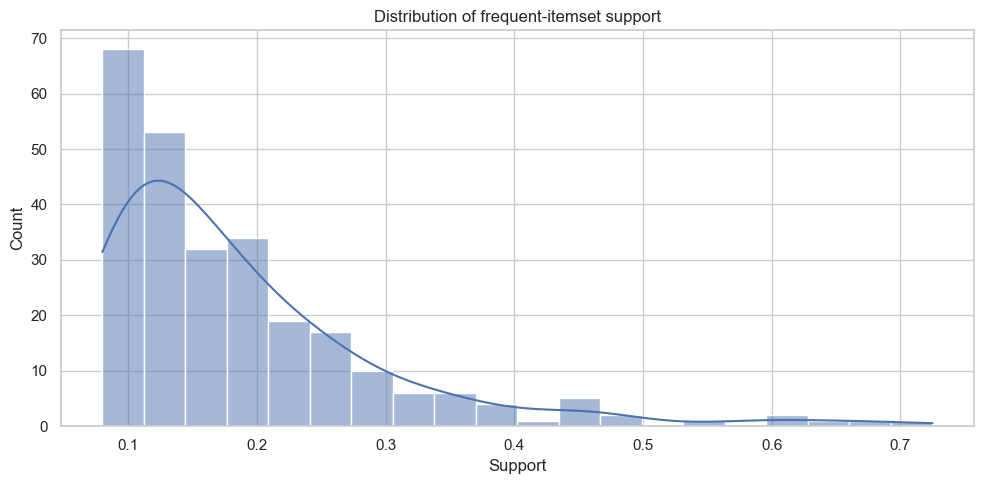

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(frequent_itemsets["support"], bins=20, kde=True)
plt.xlabel("Support")
plt.title("Distribution of frequent-itemset support")
plt.tight_layout()
plt.show()

## 6. Generate association rules

`metric="confidence"` filters rules by confidence. We then sort by lift and inspect the strongest
relationships.

In [6]:
rules = association_rules(
    frequent_itemsets.drop(columns="length"),
    metric="confidence",
    min_threshold=0.5,
)

rules["antecedents_str"] = rules["antecedents"].apply(lambda items: ", ".join(sorted(items)))
rules["consequents_str"] = rules["consequents"].apply(lambda items: ", ".join(sorted(items)))

rules[[
    "antecedents_str", "consequents_str", "support", "confidence", "lift", "leverage", "conviction"
]].sort_values("lift", ascending=False).head(15).round(4)

,antecedents_str,consequents_str,support,confidence,lift,leverage,conviction
1265,"beer, butter, milk, salsa","bread, cereal, chips",0.1225,0.6364,3.7992,0.0903,2.2894
1293,"bread, cereal, chips","beer, butter, milk, salsa",0.1225,0.7313,3.7992,0.0903,3.0057
1723,"beer, butter, coffee, salsa","bread, chips, milk",0.0875,0.8140,3.7858,0.0644,4.2194
1252,"beer, bread, milk, salsa","butter, cereal, chips",0.1225,0.6712,3.7816,0.0901,2.5018
1300,"butter, cereal, chips","beer, bread, milk, salsa",0.1225,0.6901,3.7816,0.0901,2.6383
1296,"bread, chips, milk","beer, butter, cereal, salsa",0.1225,0.5698,3.7362,0.0897,1.9699
1260,"beer, butter, cereal, salsa","bread, chips, milk",0.1225,0.8033,3.7362,0.0897,3.9904
1302,"butter, chips, milk","beer, bread, cereal, salsa",0.1225,0.5385,3.7135,0.0895,1.8525
1248,"beer, bread, cereal, salsa","butter, chips, milk",0.1225,0.8448,3.7135,0.0895,4.9783
1273,"beer, bread, chips, milk","butter, cereal, salsa",0.1225,0.6806,3.5819,0.0883,2.5357


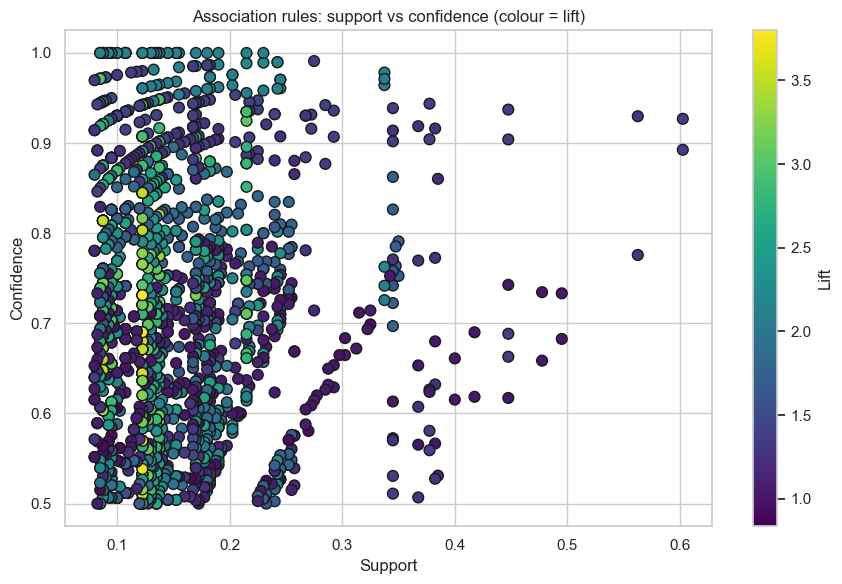

In [7]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    rules["support"], rules["confidence"], c=rules["lift"],
    cmap="viridis", s=60, edgecolor="k"
)
plt.colorbar(scatter, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association rules: support vs confidence (colour = lift)")
plt.tight_layout()
plt.show()

## 7. FP-Growth

FP-Growth produces the same frequent itemsets without candidate generation. For this small dataset
the difference is negligible, but it matters on large transaction logs.

In [8]:
fp_itemsets = fpgrowth(basket_df, min_support=0.08, use_colnames=True)
fp_itemsets["length"] = fp_itemsets["itemsets"].apply(len)

apriori_sets = set(map(frozenset, frequent_itemsets["itemsets"]))
fp_sets = set(map(frozenset, fp_itemsets["itemsets"]))
print("Frequent itemsets found by Apriori:", len(apriori_sets))
print("Frequent itemsets found by FP-Growth:", len(fp_sets))
print("Identical itemsets:", apriori_sets == fp_sets)

Frequent itemsets found by Apriori: 263
Frequent itemsets found by FP-Growth: 263
Identical itemsets: True


## 8. Filtering rules for action

High lift alone is not enough. A useful rule should also:

- have enough support to matter,
- involve items that are actionable or profitable,
- pass business constraints (for example, not already bundled),
- be stable across time and customer segments.

We filter for rules with lift above 1.5 and confidence above 0.7.

In [9]:
actionable = rules[
    (rules["lift"] > 1.5) & (rules["confidence"] > 0.7)
][["antecedents_str", "consequents_str", "support", "confidence", "lift"]]

actionable.sort_values("lift", ascending=False).round(4).head(20)

,antecedents_str,consequents_str,support,confidence,lift
1293,"bread, cereal, chips","beer, butter, milk, salsa",0.1225,0.7313,3.7992
1723,"beer, butter, coffee, salsa","bread, chips, milk",0.0875,0.8140,3.7858
1260,"beer, butter, cereal, salsa","bread, chips, milk",0.1225,0.8033,3.7362
1248,"beer, bread, cereal, salsa","butter, chips, milk",0.1225,0.8448,3.7135
1717,"beer, bread, coffee, salsa","butter, chips, milk",0.0875,0.8140,3.5778
1734,"beer, butter, chips, coffee","bread, milk, salsa",0.0875,0.8140,3.5389
1269,"beer, bread, cereal, chips","butter, milk, salsa",0.1225,0.8448,3.5201
1279,"beer, butter, cereal, chips","bread, milk, salsa",0.1225,0.8033,3.4925
1728,"beer, bread, chips, coffee","butter, milk, salsa",0.0875,0.8140,3.3915
897,"bread, cereal, chips","beer, butter, salsa",0.1375,0.8209,3.3506


## 9. Practical caveats

- **Rare items**: low support produces many spurious rules.
- **Common consequents**: high confidence can be trivial; always check lift.
- **Multiple comparisons**: the number of possible rules explodes; validate findings on new data.
- **Temporal effects**: promotions and seasons change associations.
- **Causality**: a rule is a co-occurrence pattern, not proof that X causes Y.
- **Privacy**: transaction data can be sensitive; aggregate and minimise.

## Key takeaways

- Association rules summarise co-occurrence in transactional data.
- Support measures prevalence; confidence measures rule strength; lift measures surprise.
- Apriori is intuitive; FP-Growth is usually faster on large data.
- Filter by support, confidence, lift, and business constraints.
- Validate discovered rules on fresh data before acting on them.

## Exercises

1. Lower `min_support` to 0.02 and observe the number of itemsets and rules.
2. Find rules with lift below 1 and explain what negative association means.
3. Add a seasonal item and see how rules change when it appears only in some months.
4. Compare Apriori and FP-Growth runtime on a larger synthetic dataset.
5. Design a cross-selling campaign from the top three actionable rules.